In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score
)
from sklearn.inspection import permutation_importance
from sklearn.base import clone

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestRegressor
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [2]:
# Consistent, professional visual style
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)

COLORS = {
    "navy": "#17365D",
    "blue": "#2878B5",
    "teal": "#159D91",
    "green": "#55A868",
    "gold": "#E3A018",
    "orange": "#E87535",
    "red": "#C44E52",
    "purple": "#8172B3",
    "grey": "#7F8C8D",
    "light": "#EAF2F8"
}

CLASS_COLORS = {
    "Low": COLORS["teal"],
    "Medium": COLORS["gold"],
    "High": COLORS["red"]
}

sns.set_palette([
    COLORS["blue"], COLORS["teal"], COLORS["orange"],
    COLORS["purple"], COLORS["green"], COLORS["red"]
])

RANDOM_STATE = 42

In [3]:
# Load the dataset
FILE_PATH = r"D:\irrigation_prediction.csv"
df = pd.read_csv(FILE_PATH)

In [4]:
df

,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,Clay,6.14,36.48,0.42,2.17,21.90,31.19,1167.70,4.01,1.97,Wheat,Vegetative,Rabi,Rainfed,Reservoir,4.73,Yes,1.98,South,Low
1,Silt,6.41,50.56,0.38,0.23,36.50,26.01,831.28,10.72,16.82,Maize,Flowering,Zaid,Canal,Groundwater,12.22,Yes,33.56,Central,Medium
2,Sandy,7.71,40.07,1.09,2.18,41.83,76.41,1844.45,7.75,19.03,Cotton,Harvest,Rabi,Drip,Reservoir,5.52,Yes,34.62,South,Low
3,Clay,5.96,12.75,1.56,0.40,37.22,43.32,306.26,8.90,11.44,Wheat,Sowing,Kharif,Canal,Reservoir,1.43,Yes,84.03,North,Medium
4,Clay,7.76,18.58,0.95,2.52,22.38,86.44,1875.63,10.39,11.26,Cotton,Sowing,Zaid,Canal,River,2.52,No,60.86,South,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,Silt,7.01,26.67,0.86,0.76,27.61,52.20,1075.12,7.41,19.66,Sugarcane,Sowing,Kharif,Drip,Groundwater,2.62,Yes,92.44,South,Low
9996,Clay,5.40,49.44,0.90,1.19,34.03,52.31,1591.84,9.86,5.66,Maize,Sowing,Kharif,Rainfed,Groundwater,4.87,No,15.46,South,Low
9997,Loamy,4.97,60.63,0.99,1.30,36.68,68.16,2384.87,10.75,13.40,Potato,Harvest,Kharif,Canal,Groundwater,10.08,Yes,116.36,North,Low
9998,Loamy,7.12,44.33,1.56,1.08,31.50,64.83,2397.01,4.03,3.05,Sugarcane,Harvest,Kharif,Rainfed,Reservoir,11.11,Yes,118.17,East,Low


In [5]:
# Tidy column names without changing their meaning
df.columns = df.columns.str.strip()

display(Markdown("AI-Driven Smart Irrigation: Data Analysis"))
print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
print(f"Duplicate rows: {df.duplicated().sum():,}")

display(df.head())
display(df.info())

AI-Driven Smart Irrigation: Data Analysis

Dataset loaded successfully.
Number of rows: 10,000
Number of columns: 20
Duplicate rows: 0


,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,Clay,6.14,36.48,0.42,2.17,21.90,31.19,1167.70,4.01,1.97,Wheat,Vegetative,Rabi,Rainfed,Reservoir,4.73,Yes,1.98,South,Low
1,Silt,6.41,50.56,0.38,0.23,36.50,26.01,831.28,10.72,16.82,Maize,Flowering,Zaid,Canal,Groundwater,12.22,Yes,33.56,Central,Medium
2,Sandy,7.71,40.07,1.09,2.18,41.83,76.41,1844.45,7.75,19.03,Cotton,Harvest,Rabi,Drip,Reservoir,5.52,Yes,34.62,South,Low
3,Clay,5.96,12.75,1.56,0.40,37.22,43.32,306.26,8.90,11.44,Wheat,Sowing,Kharif,Canal,Reservoir,1.43,Yes,84.03,North,Medium
4,Clay,7.76,18.58,0.95,2.52,22.38,86.44,1875.63,10.39,11.26,Cotton,Sowing,Zaid,Canal,River,2.52,No,60.86,South,Medium


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Soil_Type                10000 non-null  object 
 1   Soil_pH                  10000 non-null  float64
 2   Soil_Moisture            10000 non-null  float64
 3   Organic_Carbon           10000 non-null  float64
 4   Electrical_Conductivity  10000 non-null  float64
 5   Temperature_C            10000 non-null  float64
 6   Humidity                 10000 non-null  float64
 7   Rainfall_mm              10000 non-null  float64
 8   Sunlight_Hours           10000 non-null  float64
 9   Wind_Speed_kmh           10000 non-null  float64
 10  Crop_Type                10000 non-null  object 
 11  Crop_Growth_Stage        10000 non-null  object 
 12  Season                   10000 non-null  object 
 13  Irrigation_Type          10000 non-null  object 
 14  Water_Source           

None

# DATA QUALITY AND EXPLORATORY DATA ANALYSIS

In [6]:
TARGET = "Irrigation_Need"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Clean text values
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

# Convert the target to consistent text labels
df[TARGET] = df[TARGET].astype("string").str.strip().str.title()

# Treat common representations of missing data as missing
df = df.replace(
    ["", "NA", "N/A", "na", "null", "None", "?"], np.nan
)

# Remove rows with no usable target; predictors are imputed later
before = len(df)
df = df.dropna(subset=[TARGET]).copy()
print(f"Rows without a target removed: {before - len(df):,}")

Rows without a target removed: 0


In [7]:
# Display structure and data types
print("\nDATASET STRUCTURE")
print("-" * 60)
print("Shape:", df.shape)
display(pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Unique values": df.nunique(dropna=True)
}).sort_values("Missing (%)", ascending=False))


DATASET STRUCTURE
------------------------------------------------------------
Shape: (10000, 20)


,Data type,Missing values,Missing (%),Unique values
Soil_Type,string,0,0.0,4
Soil_pH,float64,0,0.0,341
Region,string,0,0.0,5
Previous_Irrigation_mm,float64,0,0.0,6843
Mulching_Used,string,0,0.0,2
Field_Area_hectare,float64,0,0.0,1470
Water_Source,string,0,0.0,4
Irrigation_Type,string,0,0.0,4
Season,string,0,0.0,3
Crop_Growth_Stage,string,0,0.0,4


In [8]:
print("\nDESCRIPTIVE STATISTICS")
display(df.describe(include="all").T)


DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Soil_Type,10000,4,Sandy,2536,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Soil_pH,10000.0,NaN,NaN,NaN,6.487857,0.979963,4.8,5.64,6.47,7.35,8.2
Soil_Moisture,10000.0,NaN,NaN,NaN,36.969207,16.430845,8.0,22.86,37.24,50.94,65.0
Organic_Carbon,10000.0,NaN,NaN,NaN,0.944731,0.372406,0.3,0.62,0.95,1.26,1.6
Electrical_Conductivity,10000.0,NaN,NaN,NaN,1.791963,0.984202,0.1,0.94,1.78,2.65,3.5
Temperature_C,10000.0,NaN,NaN,NaN,26.991423,8.664074,12.0,19.46,27.09,34.5,42.0
Humidity,10000.0,NaN,NaN,NaN,60.080339,20.187973,25.0,42.855,60.04,77.705,95.0
Rainfall_mm,10000.0,NaN,NaN,NaN,1252.49942,715.582201,0.38,634.155,1250.335,1880.265,2499.69
Sunlight_Hours,10000.0,NaN,NaN,NaN,7.518538,2.016077,4.0,5.76,7.56,9.26,11.0
Wind_Speed_kmh,10000.0,NaN,NaN,NaN,10.163545,5.670923,0.5,5.16,10.19,15.1,20.0


In [9]:
print("\nTARGET CLASS COUNTS")
display(df[TARGET].value_counts(dropna=False).rename("Count").to_frame())


TARGET CLASS COUNTS


,Count
Irrigation_Need,
Low,5864
Medium,3800
High,336


In [10]:
print("\nTARGET CLASS PERCENTAGES")
display(
    (df[TARGET].value_counts(normalize=True) * 100)
    .round(2).rename("Percentage").to_frame()
)


TARGET CLASS PERCENTAGES


,Percentage
Irrigation_Need,
Low,58.64
Medium,38.0
High,3.36


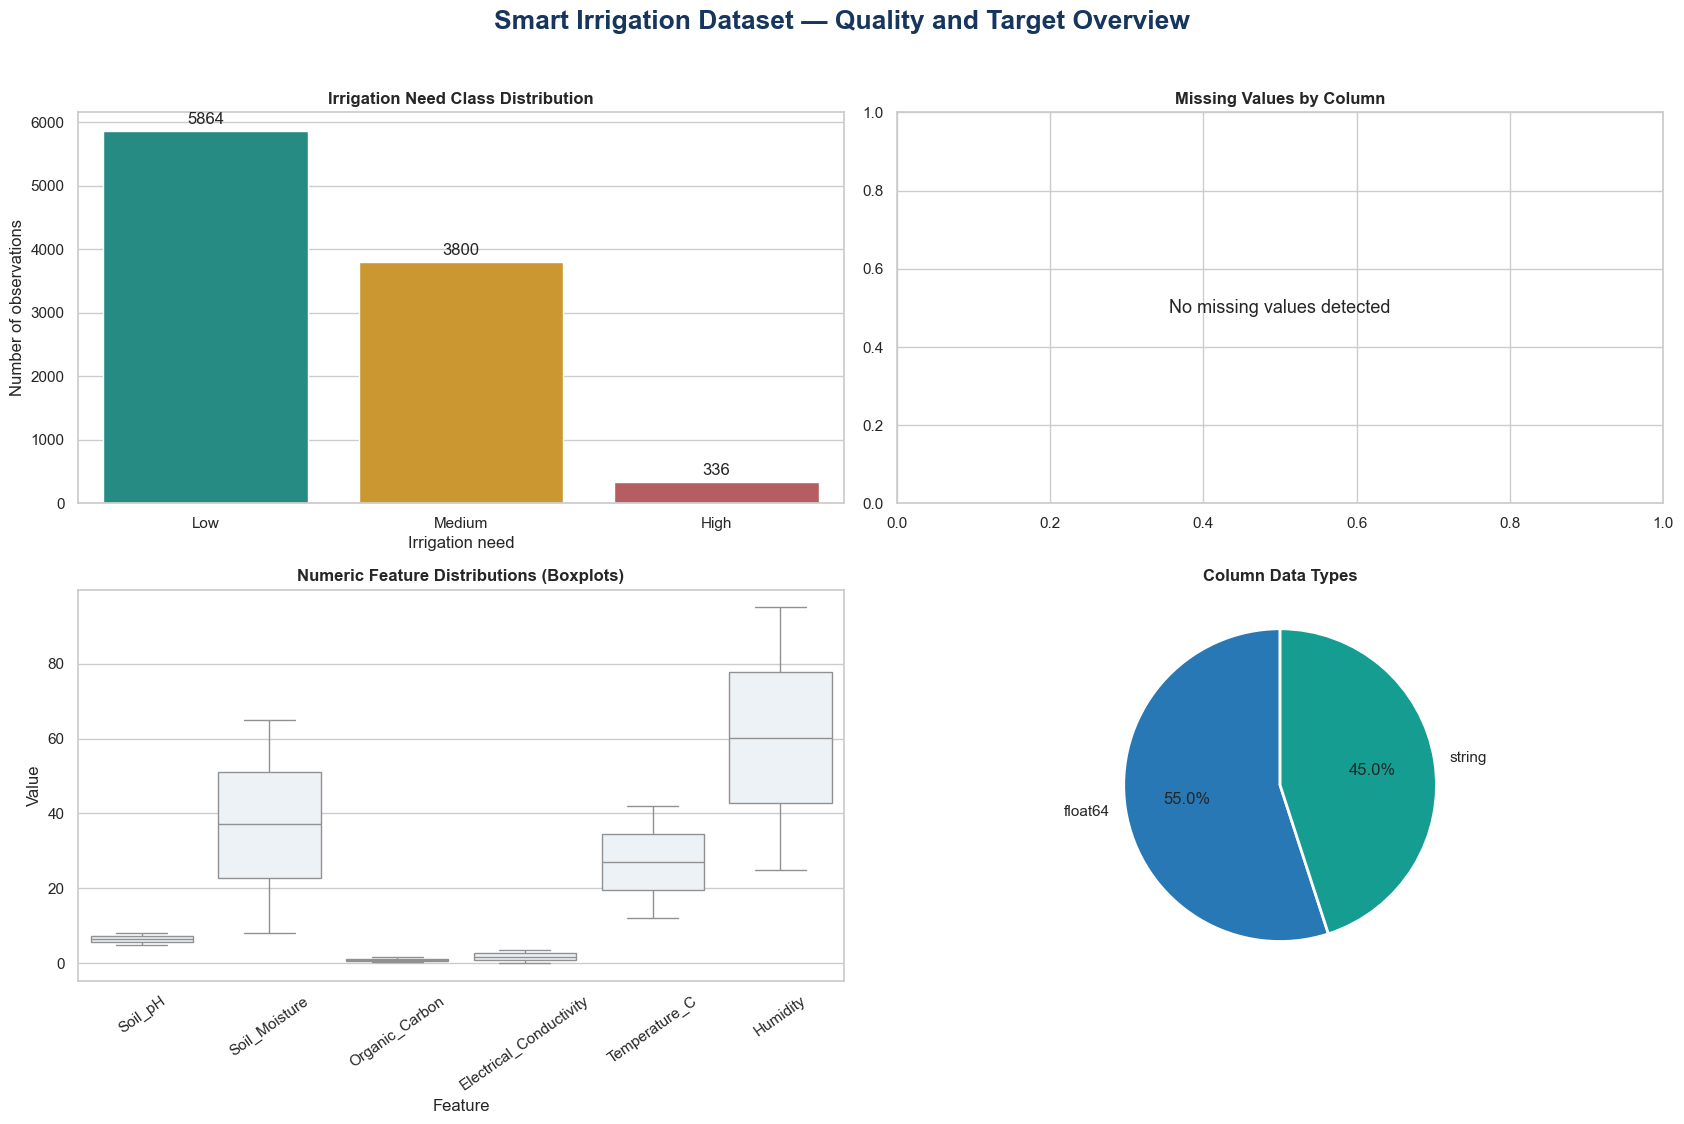

In [11]:
# Dataset overview dashboard
fig, axes = plt.subplots(2, 2, figsize=(17, 11))
fig.suptitle(
    "Smart Irrigation Dataset — Quality and Target Overview",
    fontsize=19, fontweight="bold", color=COLORS["navy"], y=1.02
)

# Panel 1: target distribution
target_order = [
    c for c in ["Low", "Medium", "High"]
    if c in df[TARGET].dropna().unique()
]
sns.countplot(
    data=df, x=TARGET, order=target_order,
    hue=TARGET, palette=CLASS_COLORS,
    legend=False, ax=axes[0, 0]
)
axes[0, 0].set_title("Irrigation Need Class Distribution", fontweight="bold")
axes[0, 0].set_xlabel("Irrigation need")
axes[0, 0].set_ylabel("Number of observations")

for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt="%.0f", padding=3)

# Panel 2: missing-value percentage
missing_pct = df.isna().mean().mul(100)
missing_pct = missing_pct[missing_pct > 0].sort_values()

if len(missing_pct):
    missing_pct.plot(
        kind="barh", ax=axes[0, 1],
        color=COLORS["orange"]
    )
    axes[0, 1].set_title("Missing Values by Column", fontweight="bold")
    axes[0, 1].set_xlabel("Missing values (%)")
else:
    axes[0, 1].text(
        0.5, 0.5, "No missing values detected",
        ha="center", va="center", fontsize=13
    )
    axes[0, 1].set_title("Missing Values by Column", fontweight="bold")

# Panel 3: numeric feature distributions
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
plot_cols = [c for c in numeric_cols if c != TARGET][:6]

if plot_cols:
    melted = df[plot_cols].melt(
        var_name="Feature", value_name="Value"
    )
    sns.boxplot(
        data=melted, x="Feature", y="Value",
        color=COLORS["light"], ax=axes[1, 0]
    )
    axes[1, 0].set_title(
        "Numeric Feature Distributions (Boxplots)", fontweight="bold"
    )
    axes[1, 0].tick_params(axis="x", rotation=35)
else:
    axes[1, 0].text(0.5, 0.5, "No numeric features", ha="center")

# Panel 4: data type summary
type_counts = df.dtypes.astype(str).value_counts()
axes[1, 1].pie(
    type_counts.values,
    labels=type_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=[COLORS["blue"], COLORS["teal"], COLORS["gold"],
            COLORS["purple"]][:len(type_counts)],
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
axes[1, 1].set_title("Column Data Types", fontweight="bold")

plt.tight_layout()
plt.show()

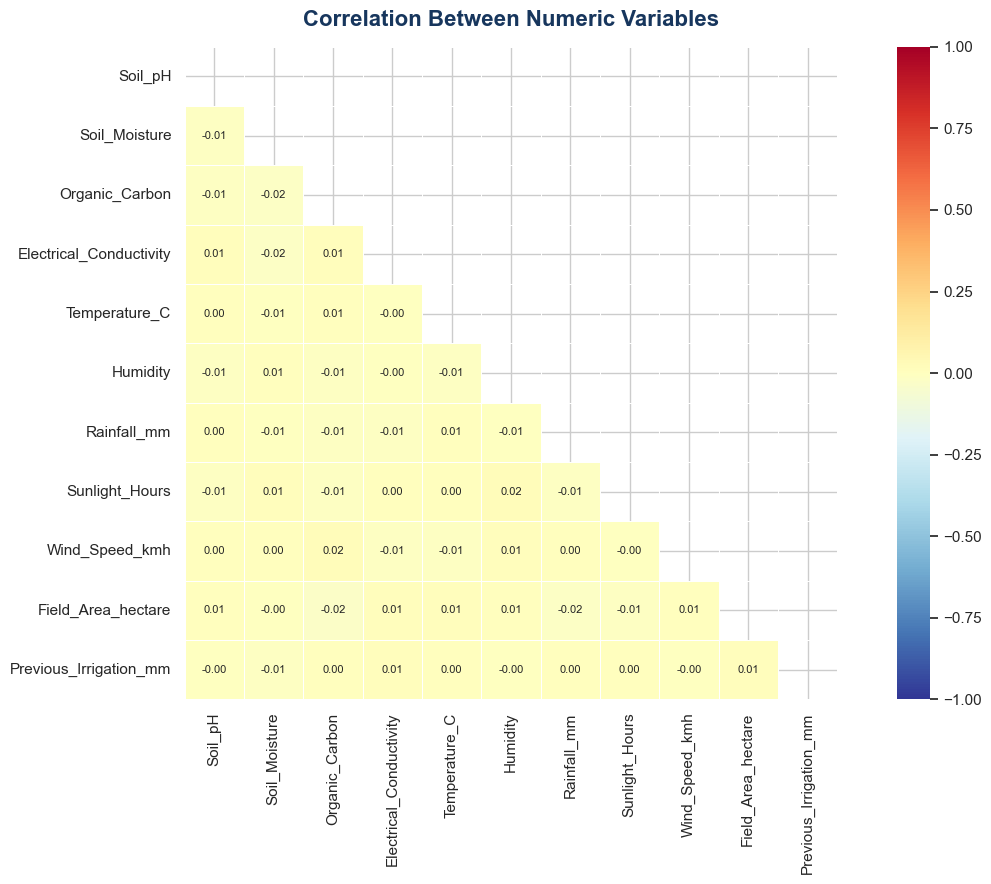

In [12]:
# Numeric correlation heatmap
if len(numeric_cols) >= 2:
    plt.figure(figsize=(13, 9))
    corr = df[numeric_cols].corr(numeric_only=True)
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(
        corr, mask=mask, cmap="RdYlBu_r",
        center=0, vmin=-1, vmax=1,
        annot=True, fmt=".2f", linewidths=0.5,
        annot_kws={"size": 8}, square=True
    )
    plt.title(
        "Correlation Between Numeric Variables",
        fontsize=16, fontweight="bold", color=COLORS["navy"], pad=15
    )
    plt.tight_layout()
    plt.show()

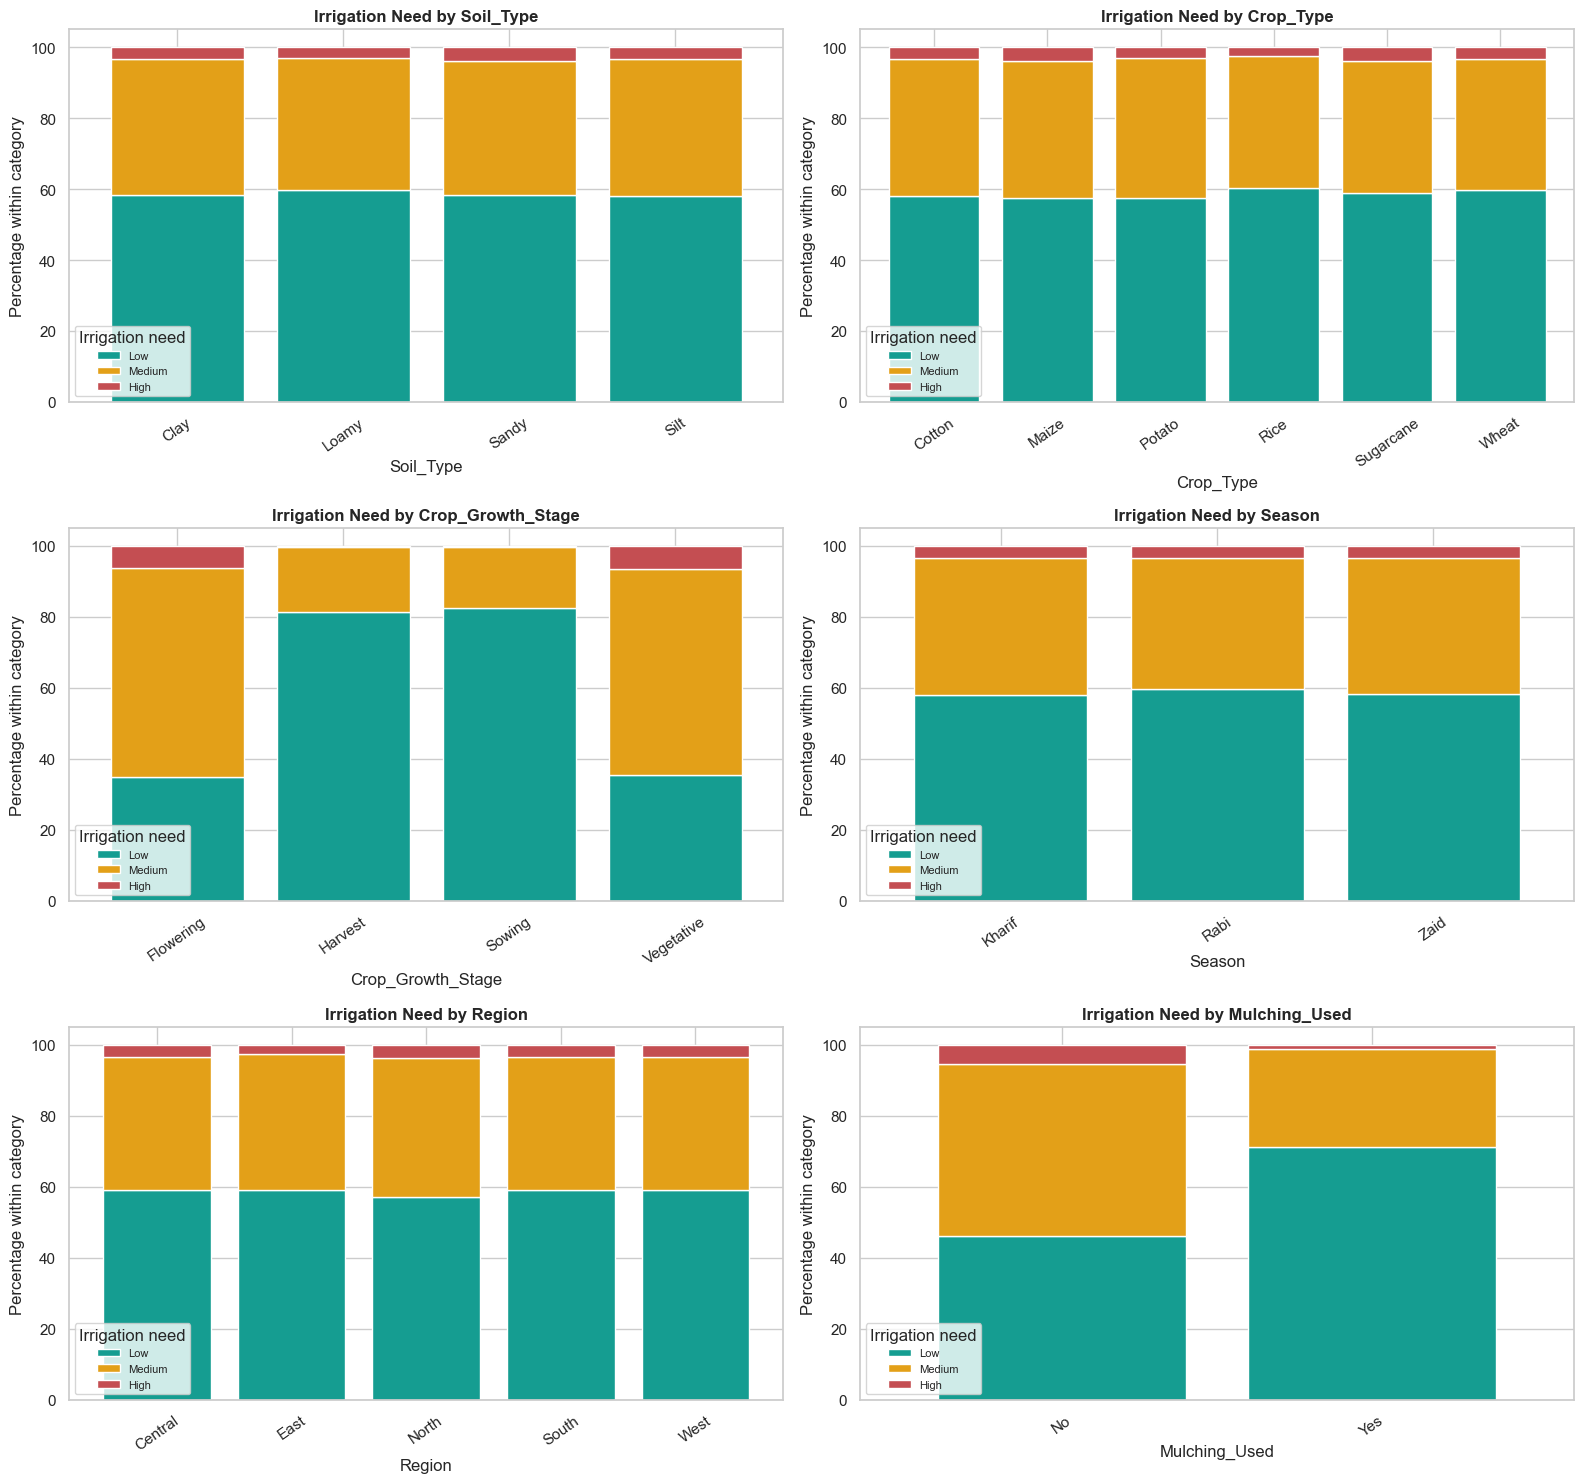

In [13]:
# Inspect categorical variables against the target
categorical_cols = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()
categorical_cols = [c for c in categorical_cols if c != TARGET]

selected_cats = [
    c for c in [
        "Soil_Type", "Crop_Type", "Crop_Growth_Stage",
        "Season", "Region", "Mulching_Used"
    ] if c in categorical_cols
]

if selected_cats:
    ncols = 2
    nrows = int(np.ceil(len(selected_cats) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(16, 5 * nrows)
    )
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, selected_cats):
        ct = pd.crosstab(df[col], df[TARGET], normalize="index") * 100
        ct = ct.reindex(columns=target_order, fill_value=0)
        ct.plot(
            kind="bar", stacked=True, ax=ax,
            color=[CLASS_COLORS.get(c, COLORS["blue"]) for c in ct.columns],
            width=0.8
        )
        ax.set_title(f"Irrigation Need by {col}", fontweight="bold")
        ax.set_ylabel("Percentage within category")
        ax.set_xlabel(col)
        ax.tick_params(axis="x", rotation=35)
        ax.legend(title="Irrigation need", fontsize=8)

    for ax in axes[len(selected_cats):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

# FEATURE SELECTION AND LEAKAGE-AWARE EXPERIMENTS

In [14]:
# Remove exact duplicate records and report how many were removed
duplicates_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Exact duplicate rows removed:", duplicates_before - len(df))

Exact duplicate rows removed: 0


In [15]:
# Keep only valid target categories
valid_classes = ["Low", "Medium", "High"]
df = df[df[TARGET].isin(valid_classes)].copy()

if df[TARGET].nunique() < 2:
    raise ValueError("At least two target classes are needed for classification.")

In [16]:
# Explicitly identify variables that could be unavailable at prediction time or could encode irrigation-management decisions.
management_cols = [
    "Irrigation_Type",
    "Water_Source",
    "Previous_Irrigation_mm"
]
management_cols = [c for c in management_cols if c in df.columns]

# Do not use target or any direct target copy as a predictor.
# Remove obvious row identifiers if present.
identifier_cols = [
    c for c in df.columns
    if c.lower() in ["id", "record_id", "sample_id", "row_id", "index"]
]

# Add any documented target proxies here after checking the dataset's documentation. Do not remove variables just because they are correlated; establish whether they reveal the outcome.
documented_target_proxies = []

base_excluded = [TARGET] + identifier_cols + documented_target_proxies

# Primary: soil, weather, crop and field attributes, excluding irrigation-management variables of uncertain prediction-time validity.
conservative_features = [
    c for c in df.columns
    if c not in base_excluded + management_cols
]

# Sensitivity experiment: adds the management variables back.
extended_features = [
    c for c in df.columns
    if c not in base_excluded
]

print("\nFEATURE SETS")
print("-" * 60)
print("Conservative feature count:", len(conservative_features))
print(conservative_features)
print("\nManagement features excluded from the primary model:", management_cols)
print("Extended feature count:", len(extended_features))


FEATURE SETS
------------------------------------------------------------
Conservative feature count: 16
['Soil_Type', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Electrical_Conductivity', 'Temperature_C', 'Humidity', 'Rainfall_mm', 'Sunlight_Hours', 'Wind_Speed_kmh', 'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Field_Area_hectare', 'Mulching_Used', 'Region']

Management features excluded from the primary model: ['Irrigation_Type', 'Water_Source', 'Previous_Irrigation_mm']
Extended feature count: 19


In [17]:
# Target classes are ordered for consistent reports and charts.
class_labels = valid_classes
y = df[TARGET].copy()

# A stratified holdout split preserves class proportions.
# The same row split is used for both feature sets.
train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print(f"\nTraining observations: {len(train_idx):,}")
print(f"Testing observations:  {len(test_idx):,}")

print("\nTraining class proportions:")
display((y_train.value_counts(normalize=True) * 100).round(2).rename("Percentage").to_frame())

print("\nTesting class proportions:")
display((y_test.value_counts(normalize=True) * 100).round(2).rename("Percentage").to_frame())


def make_preprocessor(X, scale_numeric=False):
    """Create leakage-safe preprocessing fitted only on training data."""
    numeric_features = X.select_dtypes(include=np.number).columns.tolist()
    categorical_features = [
        c for c in X.columns if c not in numeric_features
    ]

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_features),
            ("categorical", categorical_pipeline, categorical_features)
        ],
        remainder="drop"
    )


Training observations: 8,000
Testing observations:  2,000

Training class proportions:


,Percentage
Irrigation_Need,
Low,58.64
Medium,38.0
High,3.36



Testing class proportions:


,Percentage
Irrigation_Need,
Low,58.65
Medium,38.0
High,3.35


In [18]:
# Prepare the two feature-set datasets
X_conservative = df[conservative_features].copy()
X_extended = df[extended_features].copy()

Xc_train = X_conservative.iloc[train_idx]
Xc_test = X_conservative.iloc[test_idx]

Xe_train = X_extended.iloc[train_idx]
Xe_test = X_extended.iloc[test_idx]

print("\nLeakage-aware feature preparation completed.")
print("Missing predictor values are handled inside model pipelines.")
print("Imputation, encoding and scaling are fitted on training data only.")


Leakage-aware feature preparation completed.
Missing predictor values are handled inside model pipelines.
Imputation, encoding and scaling are fitted on training data only.


# TRAIN AND EVALUATE SIX CLASSIFICATION MODELS

In [19]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=120,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "SVM (RBF)": SVC(
        C=2.0,
        kernel="rbf",
        class_weight="balanced",
        cache_size=1000
    )
}

from time import perf_counter

results = []
fitted_models = {}
predictions = {}
experiment_data = {}

def evaluate_feature_set(experiment_name, X_train, X_test, y_train, y_test):
    """Fit every model and return test-set metrics and predictions."""
    local_results = []

    for model_name, classifier in models.items():
        print(f"Training {model_name} — {experiment_name} ...")

        numeric_cols = X_train.select_dtypes(include=np.number).columns
        scale_numeric = model_name in [
            "Logistic Regression", "SVM (RBF)"
        ]

        pipeline = Pipeline([
            ("preprocessor", make_preprocessor(
                X_train, scale_numeric=scale_numeric
            )),
            ("classifier", clone(classifier))
        ])

        start = perf_counter()
        pipeline.fit(X_train, y_train)
        elapsed = perf_counter() - start

        pred = pipeline.predict(X_test)

        row = {
            "Experiment": experiment_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, pred),
            "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
            "Precision (Macro)": precision_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "Recall (Macro)": recall_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "F1 (Macro)": f1_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "F1 (Weighted)": f1_score(
                y_test, pred, average="weighted", zero_division=0
            ),
            "Training Time (s)": elapsed
        }

        local_results.append(row)
        fitted_models[(experiment_name, model_name)] = pipeline
        predictions[(experiment_name, model_name)] = pred

    return local_results


experiment_data["Conservative"] = (
    Xc_train, Xc_test, y_train, y_test
)
experiment_data["Extended"] = (
    Xe_train, Xe_test, y_train, y_test
)

all_results = []

all_results.extend(evaluate_feature_set(
    "Conservative", Xc_train, Xc_test, y_train, y_test
))

all_results.extend(evaluate_feature_set(
    "Extended", Xe_train, Xe_test, y_train, y_test
))

results_df = pd.DataFrame(all_results)

# Sort by macro F1, not accuracy alone
results_df = results_df.sort_values(
    ["Experiment", "F1 (Macro)"],
    ascending=[True, False]
).reset_index(drop=True)

print("\nMODEL COMPARISON — ALL RESULTS")
display(
    results_df.style
    .format({
        "Accuracy": "{:.4f}",
        "Balanced Accuracy": "{:.4f}",
        "Precision (Macro)": "{:.4f}",
        "Recall (Macro)": "{:.4f}",
        "F1 (Macro)": "{:.4f}",
        "F1 (Weighted)": "{:.4f}",
        "Training Time (s)": "{:.2f}"
    })
    .background_gradient(
        subset=["Accuracy", "F1 (Macro)", "Balanced Accuracy"],
        cmap="YlGn"
    )
)

Training Decision Tree — Conservative ...
Training Random Forest — Conservative ...
Training Extra Trees — Conservative ...
Training Gradient Boosting — Conservative ...
Training Logistic Regression — Conservative ...
Training SVM (RBF) — Conservative ...
Training Decision Tree — Extended ...
Training Random Forest — Extended ...
Training Extra Trees — Extended ...
Training Gradient Boosting — Extended ...
Training Logistic Regression — Extended ...
Training SVM (RBF) — Extended ...

MODEL COMPARISON — ALL RESULTS


,Experiment,Model,Accuracy,Balanced Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),F1 (Weighted),Training Time (s)
0,Conservative,Decision Tree,0.9975,0.9936,0.9889,0.9936,0.9912,0.9975,0.17
1,Conservative,Gradient Boosting,0.9945,0.9453,0.9952,0.9453,0.9678,0.9943,14.08
2,Conservative,Random Forest,0.9825,0.8623,0.9861,0.8623,0.9072,0.9809,1.19
3,Conservative,SVM (RBF),0.8725,0.7632,0.7955,0.7632,0.7764,0.8727,2.08
4,Conservative,Extra Trees,0.8555,0.6761,0.8670,0.6761,0.7200,0.8507,0.79
5,Conservative,Logistic Regression,0.7875,0.7977,0.6553,0.7977,0.6902,0.7959,0.16
6,Extended,Decision Tree,0.9975,0.9936,0.9889,0.9936,0.9912,0.9975,0.16
7,Extended,Gradient Boosting,0.9940,0.9448,0.9950,0.9448,0.9674,0.9938,16.21
8,Extended,Random Forest,0.9825,0.8625,0.9860,0.8625,0.9072,0.9809,1.20
9,Extended,SVM (RBF),0.8735,0.7688,0.7983,0.7688,0.7808,0.8738,2.16


In [20]:
# Identify the leading model in each experiment
best_by_experiment = (
    results_df.sort_values("F1 (Macro)", ascending=False)
    .groupby("Experiment", sort=False)
    .head(1)
)

print("\nTOP MODEL IN EACH EXPERIMENT")
display(best_by_experiment)


TOP MODEL IN EACH EXPERIMENT


,Experiment,Model,Accuracy,Balanced Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),F1 (Weighted),Training Time (s)
0,Conservative,Decision Tree,0.9975,0.993579,0.988882,0.993579,0.991212,0.997506,0.174939
6,Extended,Decision Tree,0.9975,0.993579,0.988882,0.993579,0.991212,0.997506,0.159115


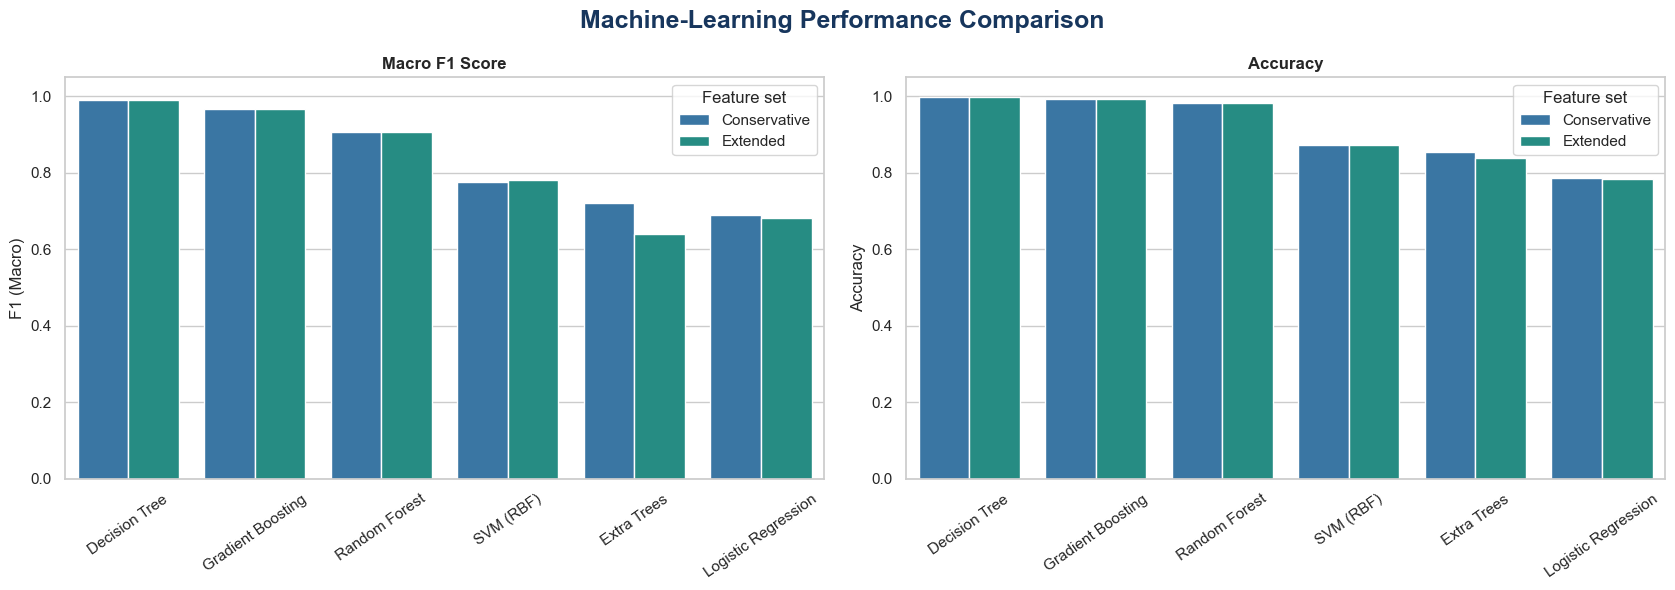

In [21]:
# Model comparison chart
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fig.suptitle(
    "Machine-Learning Performance Comparison",
    fontsize=18, fontweight="bold", color=COLORS["navy"]
)

for ax, metric, title in [
    (axes[0], "F1 (Macro)", "Macro F1 Score"),
    (axes[1], "Accuracy", "Accuracy")
]:
    sns.barplot(
        data=results_df, x="Model", y=metric,
        hue="Experiment", ax=ax
    )
    ax.set_title(title, fontweight="bold")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=35)
    ax.legend(title="Feature set")

plt.tight_layout()
plt.show()

# CONFUSION MATRICES AND CLASSIFICATION REPORTS

Primary model selected by test macro F1: Decision Tree

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low     1.0000    0.9983    0.9991      1173
      Medium     0.9961    0.9974    0.9967       760
        High     0.9706    0.9851    0.9778        67

    accuracy                         0.9975      2000
   macro avg     0.9889    0.9936    0.9912      2000
weighted avg     0.9975    0.9975    0.9975      2000



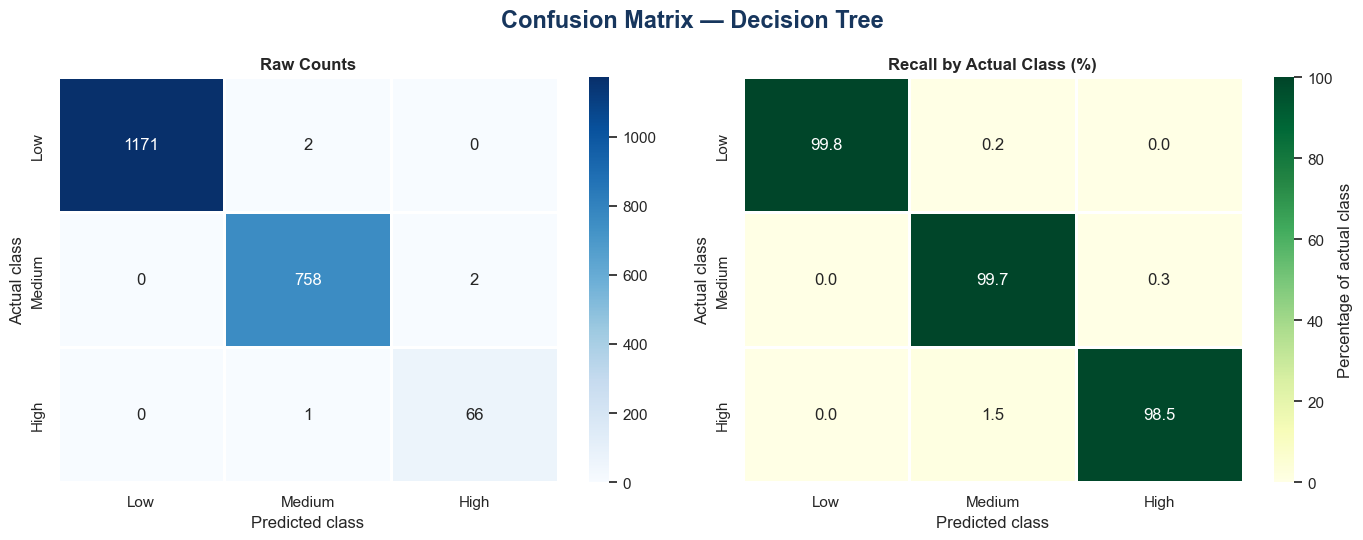

In [22]:
# Use the best model from the conservative experiment as the primary model for interpretation.
primary_candidates = results_df[
    results_df["Experiment"] == "Conservative"
].sort_values("F1 (Macro)", ascending=False)

best_primary_name = primary_candidates.iloc[0]["Model"]
best_primary_key = ("Conservative", best_primary_name)
best_primary_model = fitted_models[best_primary_key]
best_primary_predictions = predictions[best_primary_key]

print("Primary model selected by test macro F1:", best_primary_name)

print("\nDETAILED CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    best_primary_predictions,
    labels=class_labels,
    target_names=class_labels,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    y_test, best_primary_predictions, labels=class_labels
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle(
    f"Confusion Matrix — {best_primary_name}",
    fontsize=17, fontweight="bold", color=COLORS["navy"]
)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_labels, yticklabels=class_labels,
    linewidths=1, linecolor="white", ax=axes[0]
)
axes[0].set_title("Raw Counts", fontweight="bold")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("Actual class")

row_sums = cm.sum(axis=1, keepdims=True)
cm_pct = np.divide(
    cm, row_sums,
    out=np.zeros_like(cm, dtype=float),
    where=row_sums != 0
) * 100

sns.heatmap(
    cm_pct, annot=True, fmt=".1f", cmap="YlGn",
    xticklabels=class_labels, yticklabels=class_labels,
    vmin=0, vmax=100, linewidths=1,
    linecolor="white", ax=axes[1],
    cbar_kws={"label": "Percentage of actual class"}
)
axes[1].set_title("Recall by Actual Class (%)", fontweight="bold")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("Actual class")

plt.tight_layout()
plt.show()

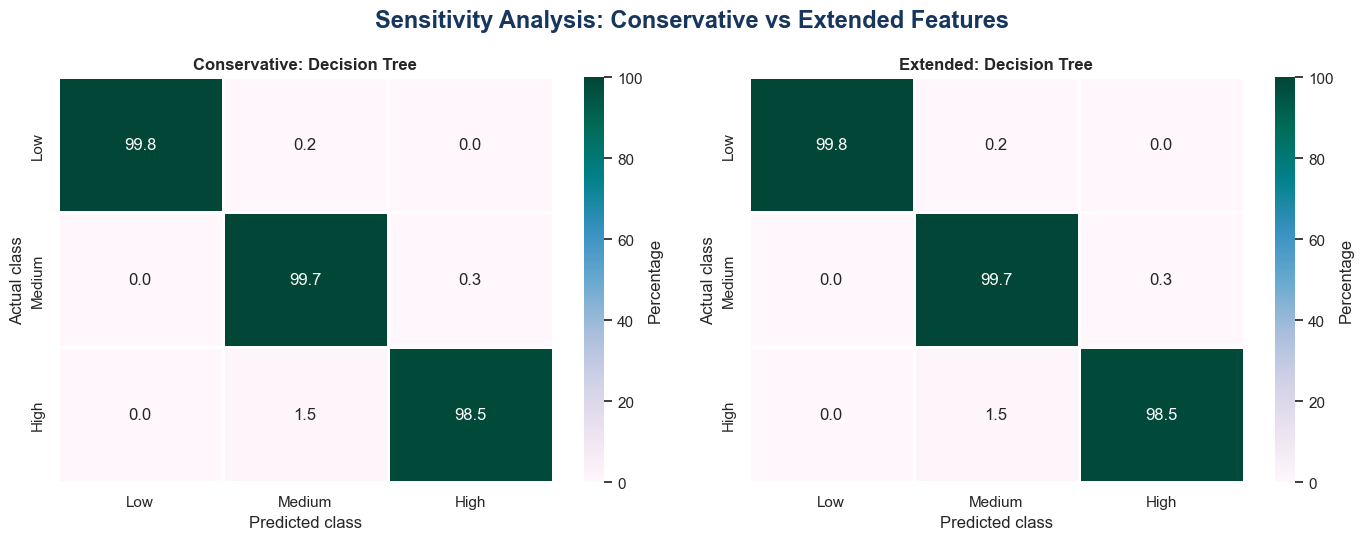

In [23]:
# Compare normalized confusion matrices for the leading model in each feature-set experiment.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle(
    "Sensitivity Analysis: Conservative vs Extended Features",
    fontsize=17, fontweight="bold", color=COLORS["navy"]
)

for ax, experiment in zip(axes, ["Conservative", "Extended"]):
    best_row = results_df[
        results_df["Experiment"] == experiment
    ].sort_values("F1 (Macro)", ascending=False).iloc[0]

    model_name = best_row["Model"]
    pred = predictions[(experiment, model_name)]

    matrix = confusion_matrix(
        y_test, pred, labels=class_labels, normalize="true"
    ) * 100

    sns.heatmap(
        matrix, annot=True, fmt=".1f", cmap="PuBuGn",
        vmin=0, vmax=100,
        xticklabels=class_labels,
        yticklabels=class_labels,
        linewidths=1, ax=ax,
        cbar_kws={"label": "Percentage"}
    )
    ax.set_title(
        f"{experiment}: {model_name}",
        fontweight="bold"
    )
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()

# PERMUTATION FEATURE IMPORTANCE

Calculating permutation importance...
This may take a little time.

TOP 15 PREDICTIVE FEATURES


,Feature,Importance Mean,Importance SD
2,Soil_Moisture,0.34099,0.00833
11,Crop_Growth_Stage,0.33025,0.01038
7,Rainfall_mm,0.25868,0.01038
5,Temperature_C,0.19327,0.01270
9,Wind_Speed_kmh,0.18210,0.00862
14,Mulching_Used,0.17758,0.00898
0,Soil_Type,0.00000,0.00000
1,Soil_pH,0.00000,0.00000
3,Organic_Carbon,0.00000,0.00000
4,Electrical_Conductivity,0.00000,0.00000


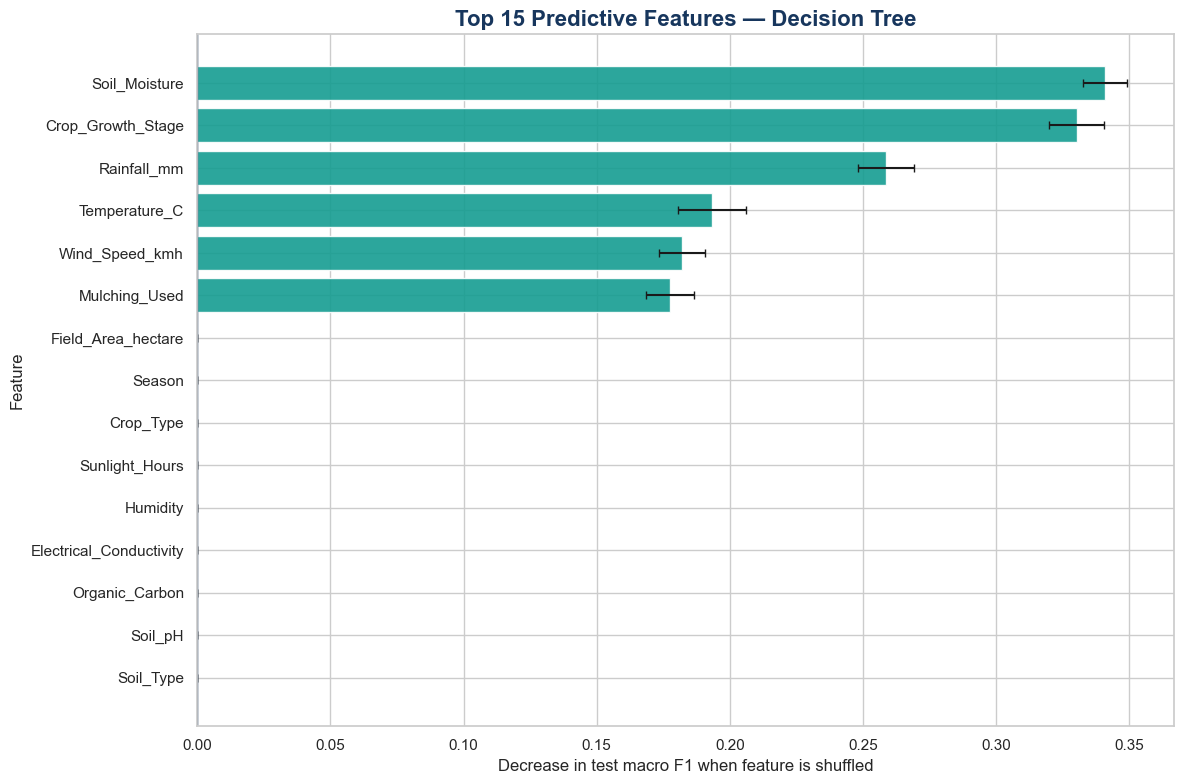


Interpretation: Larger positive values indicate that shuffling the feature reduced the model's macro F1. Values near zero suggest little measurable contribution under this test-set experiment. Negative values can occur due to sampling variation or noise.


In [24]:
print("Calculating permutation importance...")
print("This may take a little time.")

importance_result = permutation_importance(
    best_primary_model,
    Xc_test,
    y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": Xc_test.columns,
    "Importance Mean": importance_result.importances_mean,
    "Importance SD": importance_result.importances_std
}).sort_values("Importance Mean", ascending=False)

print("\nTOP 15 PREDICTIVE FEATURES")
display(
    importance_df.head(15).style.format({
        "Importance Mean": "{:.5f}",
        "Importance SD": "{:.5f}"
    }).background_gradient(
        subset=["Importance Mean"], cmap="YlGnBu"
    )
)

top_features = importance_df.head(15).sort_values("Importance Mean")

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance SD"],
    color=[
        COLORS["teal"] if x >= 0 else COLORS["red"]
        for x in top_features["Importance Mean"]
    ],
    capsize=3,
    alpha=0.9
)

ax.axvline(0, color=COLORS["navy"], linewidth=1)
ax.set_title(
    f"Top 15 Predictive Features — {best_primary_name}",
    fontsize=16, fontweight="bold", color=COLORS["navy"]
)
ax.set_xlabel("Decrease in test macro F1 when feature is shuffled")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

print(
    "\nInterpretation: Larger positive values indicate that shuffling "
    "the feature reduced the model's macro F1. Values near zero suggest "
    "little measurable contribution under this test-set experiment. "
    "Negative values can occur due to sampling variation or noise."
)

# EXPERIMENT 1: FEATURE ABLATION / LEAKAGE AUDIT

In [25]:
from sklearn.metrics import f1_score, accuracy_score

# Features identified through permutation importance
suspicious_features = [
    "Soil_Moisture",
    "Crop_Growth_Stage",
    "Rainfall_mm",
    "Temperature_C",
    "Wind_Speed_kmh",
    "Mulching_Used"
]

# Only retain features that exist in the dataset
suspicious_features = [
    c for c in suspicious_features
    if c in X_conservative.columns
]

# Use a fixed model for fair comparisons
audit_model = DecisionTreeClassifier(
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

feature_experiments = {
    "All conservative features": conservative_features,
    "Without management-related variables": conservative_features,
    "Six influential features only": suspicious_features,
    "Without six influential features": [
        c for c in conservative_features
        if c not in suspicious_features
    ]
}

# Also remove each influential feature individually
for feature in suspicious_features:
    feature_experiments[
        f"Without {feature}"
    ] = [
        c for c in conservative_features
        if c != feature
    ]

ablation_results = []

for experiment, features in feature_experiments.items():

    if len(features) == 0:
        continue

    X_train_audit = df.iloc[train_idx][features]
    X_test_audit = df.iloc[test_idx][features]

    pipeline = Pipeline([
        ("preprocessor", make_preprocessor(
            X_train_audit,
            scale_numeric=False
        )),
        ("classifier", clone(audit_model))
    ])

    pipeline.fit(X_train_audit, y_train)

    predictions_audit = pipeline.predict(X_test_audit)

    ablation_results.append({
        "Experiment": experiment,
        "Number of features": len(features),
        "Accuracy": accuracy_score(
            y_test, predictions_audit
        ),
        "Macro F1": f1_score(
            y_test,
            predictions_audit,
            average="macro",
            zero_division=0
        )
    })

ablation_df = pd.DataFrame(ablation_results)

display(
    ablation_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro F1": "{:.4f}"
    }).background_gradient(
        subset=["Accuracy", "Macro F1"],
        cmap="YlGn"
    )
)

,Experiment,Number of features,Accuracy,Macro F1
0,All conservative features,16,0.9975,0.9912
1,Without management-related variables,16,0.9975,0.9912
2,Six influential features only,6,0.9975,0.9912
3,Without six influential features,10,0.4025,0.3053
4,Without Soil_Moisture,15,0.7145,0.5987
5,Without Crop_Growth_Stage,15,0.7310,0.7005
6,Without Rainfall_mm,15,0.8380,0.6890
7,Without Temperature_C,15,0.8345,0.7753
8,Without Wind_Speed_kmh,15,0.8690,0.8419
9,Without Mulching_Used,15,0.8510,0.8157


# EXPERIMENT 2: SIMPLE RULE-BASED BASELINE

In [26]:
from sklearn.tree import export_text

rule_baseline = Pipeline([
    ("preprocessor", make_preprocessor(
        Xc_train,
        scale_numeric=False
    )),
    ("classifier", DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=30,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

rule_baseline.fit(Xc_train, y_train)

rule_predictions = rule_baseline.predict(Xc_test)

print("RULE-BASED BASELINE RESULTS")
print("-" * 50)

print(
    "Accuracy:",
    round(accuracy_score(y_test, rule_predictions), 4)
)

print(
    "Macro F1:",
    round(f1_score(
        y_test,
        rule_predictions,
        average="macro",
        zero_division=0
    ), 4)
)

# Display the learned decision rules
preprocessor = rule_baseline.named_steps["preprocessor"]
tree_model = rule_baseline.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()

print("\nLEARNED CLASSIFICATION RULES")
print("-" * 50)

print(export_text(
    tree_model,
    feature_names=list(feature_names)
))

RULE-BASED BASELINE RESULTS
--------------------------------------------------
Accuracy: 0.574
Macro F1: 0.4136

LEARNED CLASSIFICATION RULES
--------------------------------------------------
|--- numeric__Soil_Moisture <= 24.98
|   |--- numeric__Rainfall_mm <= 299.65
|   |   |--- class: High
|   |--- numeric__Rainfall_mm >  299.65
|   |   |--- class: High
|--- numeric__Soil_Moisture >  24.98
|   |--- numeric__Rainfall_mm <= 299.79
|   |   |--- class: Medium
|   |--- numeric__Rainfall_mm >  299.79
|   |   |--- class: Low



# EXPERIMENT 3: GROUP-WISE GENERALISATION TEST

In [27]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

def evaluate_group_transfer(group_column):

    print(f"\nGROUP-WISE TEST: {group_column}")
    print("=" * 65)

    # Remove the group identifier from the predictors
    features = [
        c for c in conservative_features
        if c != group_column
    ]

    X_group = df[features].copy()
    groups = df[group_column].copy()

    logo = LeaveOneGroupOut()

    group_results = []

    for train_positions, test_positions in logo.split(
        X_group, y, groups
    ):

        X_train_group = X_group.iloc[train_positions]
        X_test_group = X_group.iloc[test_positions]

        y_train_group = y.iloc[train_positions]
        y_test_group = y.iloc[test_positions]

        held_out_group = groups.iloc[
            test_positions
        ].iloc[0]

        # Build a fresh pipeline for every split
        pipeline = Pipeline([
            ("preprocessor", make_preprocessor(
                X_train_group,
                scale_numeric=False
            )),
            ("classifier", DecisionTreeClassifier(
                max_depth=12,
                min_samples_leaf=5,
                class_weight="balanced",
                random_state=RANDOM_STATE
            ))
        ])

        pipeline.fit(X_train_group, y_train_group)

        group_predictions = pipeline.predict(X_test_group)

        group_results.append({
            "Group type": group_column,
            "Unseen group": held_out_group,
            "Test observations": len(test_positions),
            "Accuracy": accuracy_score(
                y_test_group, group_predictions
            ),
            "Macro F1": f1_score(
                y_test_group,
                group_predictions,
                labels=valid_classes,
                average="macro",
                zero_division=0
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_test_group, group_predictions
            )
        })

    return pd.DataFrame(group_results)


# Run three separate transfer experiments
region_results = evaluate_group_transfer("Region")

crop_results = evaluate_group_transfer("Crop_Type")

soil_results = evaluate_group_transfer("Soil_Type")

group_results_df = pd.concat(
    [region_results, crop_results, soil_results],
    ignore_index=True
)

print("\nALL GROUP-WISE GENERALISATION RESULTS")

display(
    group_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Balanced Accuracy": "{:.4f}"
    }).background_gradient(
        subset=["Macro F1"],
        cmap="YlGn"
    )
)


GROUP-WISE TEST: Region

GROUP-WISE TEST: Crop_Type

GROUP-WISE TEST: Soil_Type

ALL GROUP-WISE GENERALISATION RESULTS


,Group type,Unseen group,Test observations,Accuracy,Macro F1,Balanced Accuracy
0,Region,Central,1987,0.9965,0.9886,0.9927
1,Region,East,1994,0.9910,0.9657,0.9810
2,Region,North,1900,0.9963,0.9906,0.9926
3,Region,South,2102,0.9962,0.9888,0.9886
4,Region,West,2017,0.9975,0.9871,0.9934
5,Crop_Type,Cotton,1595,0.9969,0.9863,0.9862
6,Crop_Type,Maize,1694,0.9970,0.9889,0.9932
7,Crop_Type,Potato,1663,0.9946,0.9838,0.9835
8,Crop_Type,Rice,1711,0.9971,0.9908,0.9976
9,Crop_Type,Sugarcane,1678,0.9952,0.9846,0.9867


# EXPERIMENT 4: REPEATED STRATIFIED CROSS-VALIDATION

In [28]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.base import clone
from scipy.stats import t

# Select the best model from the conservative experiment
primary_model_template = models[best_primary_name]

# Determine whether numerical scaling is required
scale_numeric = best_primary_name in [
    "Logistic Regression", "SVM (RBF)"
]

# CREATE cv_pipeline BEFORE USING IT
cv_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(
        Xc_train,
        scale_numeric=scale_numeric
    )),
    ("classifier", clone(primary_model_template))
])

# Five-fold cross-validation repeated five times
repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=RANDOM_STATE
)

print("Running 5-fold cross-validation repeated 5 times...")
print("Total validation runs: 25")

# Evaluate using training data only
repeated_results = cross_validate(
    cv_pipeline,
    Xc_train,
    y_train,
    cv=repeated_cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "f1_macro": "f1_macro",
        "f1_weighted": "f1_weighted"
    },
    return_train_score=False,
    n_jobs=1
)

# Summarise evaluation metrics
metric_names = {
    "test_accuracy": "Accuracy",
    "test_balanced_accuracy": "Balanced Accuracy",
    "test_f1_macro": "Macro F1",
    "test_f1_weighted": "Weighted F1"
}

cv_summary_rows = []

for metric_key, metric_name in metric_names.items():

    scores = repeated_results[metric_key]

    mean_score = scores.mean()
    std_score = scores.std(ddof=1)

    n = len(scores)
    standard_error = std_score / np.sqrt(n)

    margin = t.ppf(
        0.975, df=n - 1
    ) * standard_error

    cv_summary_rows.append({
        "Metric": metric_name,
        "Mean": mean_score,
        "Standard deviation": std_score,
        "Approx. lower 95%": mean_score - margin,
        "Approx. upper 95%": mean_score + margin
    })

repeated_cv_summary = pd.DataFrame(cv_summary_rows)

print("\nREPEATED STRATIFIED CROSS-VALIDATION RESULTS")
print("=" * 65)

display(
    repeated_cv_summary.style.format({
        "Mean": "{:.4f}",
        "Standard deviation": "{:.4f}",
        "Approx. lower 95%": "{:.4f}",
        "Approx. upper 95%": "{:.4f}"
    }).background_gradient(
        subset=["Mean"], cmap="YlGn"
    )
)

print("\nCross-validation completed successfully.")

Running 5-fold cross-validation repeated 5 times...
Total validation runs: 25

REPEATED STRATIFIED CROSS-VALIDATION RESULTS


,Metric,Mean,Standard deviation,Approx. lower 95%,Approx. upper 95%
0,Accuracy,0.9943,0.0023,0.9934,0.9953
1,Balanced Accuracy,0.9862,0.0101,0.9820,0.9904
2,Macro F1,0.9784,0.0095,0.9745,0.9823
3,Weighted F1,0.9944,0.0022,0.9935,0.9953



Cross-validation completed successfully.


# EXPERIMENT 5: ORDINAL-AWARE EVALUATION

In [29]:
from sklearn.metrics import (
    mean_absolute_error,
    cohen_kappa_score
)

ordinal_mapping = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

actual_ordinal = y_test.map(ordinal_mapping).to_numpy()

ordinal_results = []

for (experiment, model_name), pred in predictions.items():

    predicted_ordinal = (
        pd.Series(pred)
        .map(ordinal_mapping)
        .to_numpy()
    )

    ordinal_results.append({
        "Experiment": experiment,
        "Model": model_name,
        "Ordinal MAE": mean_absolute_error(
            actual_ordinal,
            predicted_ordinal
        ),
        "Quadratic Weighted Kappa": cohen_kappa_score(
            actual_ordinal,
            predicted_ordinal,
            weights="quadratic"
        )
    })

ordinal_df = pd.DataFrame(ordinal_results)

display(
    ordinal_df.style.format({
        "Ordinal MAE": "{:.4f}",
        "Quadratic Weighted Kappa": "{:.4f}"
    }).background_gradient(
        subset=["Quadratic Weighted Kappa"],
        cmap="YlGn"
    )
)

,Experiment,Model,Ordinal MAE,Quadratic Weighted Kappa
0,Conservative,Decision Tree,0.0025,0.9960
1,Conservative,Random Forest,0.0175,0.9708
2,Conservative,Extra Trees,0.1445,0.7506
3,Conservative,Gradient Boosting,0.0055,0.9911
4,Conservative,Logistic Regression,0.2125,0.7115
5,Conservative,SVM (RBF),0.1275,0.7936
6,Extended,Decision Tree,0.0025,0.9960
7,Extended,Random Forest,0.0175,0.9708
8,Extended,Extra Trees,0.1600,0.7169
9,Extended,Gradient Boosting,0.0060,0.9903


# STRATIFIED CROSS-VALIDATION ON TRAINING DATA ONLY

In [30]:
primary_model_template = models[best_primary_name]

scale_numeric = best_primary_name in [
    "Logistic Regression", "SVM (RBF)"
]

cv_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(
        Xc_train, scale_numeric=scale_numeric
    )),
    ("classifier", clone(primary_model_template))
])

minimum_class_count = int(y_train.value_counts().min())
n_splits = min(5, minimum_class_count)

if n_splits >= 2:
    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    cv_results = cross_validate(
        cv_pipeline,
        Xc_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy",
            "f1_macro": "f1_macro",
            "f1_weighted": "f1_weighted"
        },
        return_train_score=False,
        n_jobs=1
    )

    cv_summary = pd.DataFrame({
        "Metric": [
            "Accuracy",
            "Balanced accuracy",
            "Macro F1",
            "Weighted F1"
        ],
        "Mean CV score": [
            cv_results["test_accuracy"].mean(),
            cv_results["test_balanced_accuracy"].mean(),
            cv_results["test_f1_macro"].mean(),
            cv_results["test_f1_weighted"].mean()
        ],
        "Standard deviation": [
            cv_results["test_accuracy"].std(),
            cv_results["test_balanced_accuracy"].std(),
            cv_results["test_f1_macro"].std(),
            cv_results["test_f1_weighted"].std()
        ]
    })

    print(f"Stratified {n_splits}-fold CV results on training data:")
    display(
        cv_summary.style.format({
            "Mean CV score": "{:.4f}",
            "Standard deviation": "{:.4f}"
        }).background_gradient(
            subset=["Mean CV score"], cmap="YlGn"
        )
    )
else:
    print(
        "Cross-validation was skipped because the smallest "
        "training class has fewer than two observations."
    )

Stratified 5-fold CV results on training data:


,Metric,Mean CV score,Standard deviation
0,Accuracy,0.9949,0.0019
1,Balanced accuracy,0.9867,0.0075
2,Macro F1,0.9804,0.0061
3,Weighted F1,0.9949,0.0019


# INTERACTIVE PREDICTION EXAMPLE

In [31]:
def predict_irrigation(row_number):
    """Predict irrigation need for an existing dataset observation."""
    row_number = int(row_number)

    if row_number < 0 or row_number >= len(df):
        raise ValueError(f"Choose a row between 0 and {len(df) - 1}.")

    observation = df.iloc[[row_number]]
    X_observation = observation[conservative_features]

    prediction = best_primary_model.predict(X_observation)[0]

    print(f"\nObservation index: {row_number}")
    print(f"Actual irrigation need: {observation[TARGET].iloc[0]}")
    print(f"Predicted irrigation need: {prediction}")

    if hasattr(best_primary_model, "predict_proba"):
        probabilities = best_primary_model.predict_proba(
            X_observation
        )[0]

        probability_df = pd.DataFrame({
            "Irrigation category": best_primary_model.classes_,
            "Predicted probability (%)": probabilities * 100
        }).sort_values("Predicted probability (%)", ascending=False)

        display(
            probability_df.style.format({
                "Predicted probability (%)": "{:.2f}%"
            }).background_gradient(
                subset=["Predicted probability (%)"], cmap="YlGn"
            )
        )

    display(observation[conservative_features + [TARGET]].T.rename(
        columns={observation.index[0]: "Observation"}
    ))

try:
    import ipywidgets as widgets
    from IPython.display import clear_output

    row_selector = widgets.IntSlider(
        value=0,
        min=0,
        max=len(df) - 1,
        step=1,
        description="Row index:",
        continuous_update=False,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="75%")
    )

    predict_button = widgets.Button(
        description="Predict irrigation need",
        button_style="success",
        icon="check"
    )

    output_area = widgets.Output()

    def on_predict_clicked(_):
        with output_area:
            clear_output(wait=True)
            predict_irrigation(row_selector.value)

    predict_button.on_click(on_predict_clicked)

    display(widgets.VBox([
        widgets.HTML(
            "<h3 style='color:#17365D'>Smart Irrigation Prediction</h3>"
            "<p>Select an observation to inspect the model prediction.</p>"
        ),
        row_selector,
        predict_button,
        output_area
    ]))

except ImportError:
    print("ipywidgets is not installed; displaying a sample prediction.")
    predict_irrigation(0)

# FINAL SUMMARY: READY FOR RESULTS INTERPRETATION

In [32]:
print("=" * 75)
print("FINAL SMART IRRIGATION CLASSIFICATION RESULTS")
print("=" * 75)

summary_columns = [
    "Experiment", "Model", "Accuracy",
    "Balanced Accuracy", "Precision (Macro)",
    "Recall (Macro)", "F1 (Macro)", "F1 (Weighted)"
]

final_summary = results_df[summary_columns].sort_values(
    ["Experiment", "F1 (Macro)"],
    ascending=[True, False]
).reset_index(drop=True)

display(
    final_summary.style.format({
        c: "{:.4f}" for c in summary_columns
        if c not in ["Experiment", "Model"]
    }).background_gradient(
        subset=["F1 (Macro)", "Accuracy"], cmap="YlGn"
    )
)

conservative_best = results_df[
    results_df["Experiment"] == "Conservative"
].sort_values("F1 (Macro)", ascending=False).iloc[0]

extended_best = results_df[
    results_df["Experiment"] == "Extended"
].sort_values("F1 (Macro)", ascending=False).iloc[0]

print("\nKEY FINDINGS")
print("-" * 75)
print(
    f"Primary model: {conservative_best['Model']}\n"
    f"Test accuracy: {conservative_best['Accuracy']:.4f}\n"
    f"Test macro F1: {conservative_best['F1 (Macro)']:.4f}\n"
    f"Test balanced accuracy: "
    f"{conservative_best['Balanced Accuracy']:.4f}"
)

print(
    f"\nBest extended-feature model: {extended_best['Model']}\n"
    f"Extended test accuracy: {extended_best['Accuracy']:.4f}\n"
    f"Extended test macro F1: {extended_best['F1 (Macro)']:.4f}"
)

f1_difference = (
    extended_best["F1 (Macro)"] -
    conservative_best["F1 (Macro)"]
)

print(
    f"\nDifference in best macro F1 (extended minus conservative): "
    f"{f1_difference:+.4f}"
)

print("\nRESEARCH INTERPRETATION")
if f1_difference > 0.02:
    print(
        "The extended feature set performed noticeably better. "
        "Investigate whether irrigation-management variables contain "
        "information that would genuinely be available at prediction time."
    )
elif f1_difference < -0.02:
    print(
        "The conservative feature set performed better. "
        "Additional management variables did not improve the best "
        "observed macro F1 in this experiment."
    )
else:
    print(
        "The best macro F1 scores were relatively similar. "
        "The simpler conservative feature set may be preferable, "
        "subject to validation and the intended prediction use case."
    )

print("\nAll outputs remain in the current notebook session.")
print("No datasets, charts, reports, or trained models were saved to disk.")

FINAL SMART IRRIGATION CLASSIFICATION RESULTS


,Experiment,Model,Accuracy,Balanced Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),F1 (Weighted)
0,Conservative,Decision Tree,0.9975,0.9936,0.9889,0.9936,0.9912,0.9975
1,Conservative,Gradient Boosting,0.9945,0.9453,0.9952,0.9453,0.9678,0.9943
2,Conservative,Random Forest,0.9825,0.8623,0.9861,0.8623,0.9072,0.9809
3,Conservative,SVM (RBF),0.8725,0.7632,0.7955,0.7632,0.7764,0.8727
4,Conservative,Extra Trees,0.8555,0.6761,0.8670,0.6761,0.7200,0.8507
5,Conservative,Logistic Regression,0.7875,0.7977,0.6553,0.7977,0.6902,0.7959
6,Extended,Decision Tree,0.9975,0.9936,0.9889,0.9936,0.9912,0.9975
7,Extended,Gradient Boosting,0.9940,0.9448,0.9950,0.9448,0.9674,0.9938
8,Extended,Random Forest,0.9825,0.8625,0.9860,0.8625,0.9072,0.9809
9,Extended,SVM (RBF),0.8735,0.7688,0.7983,0.7688,0.7808,0.8738



KEY FINDINGS
---------------------------------------------------------------------------
Primary model: Decision Tree
Test accuracy: 0.9975
Test macro F1: 0.9912
Test balanced accuracy: 0.9936

Best extended-feature model: Decision Tree
Extended test accuracy: 0.9975
Extended test macro F1: 0.9912

Difference in best macro F1 (extended minus conservative): +0.0000

RESEARCH INTERPRETATION
The best macro F1 scores were relatively similar. The simpler conservative feature set may be preferable, subject to validation and the intended prediction use case.

All outputs remain in the current notebook session.
No datasets, charts, reports, or trained models were saved to disk.


# ......................................................................................................................................................